In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

warnings.filterwarnings('ignore')

In [3]:
df = pd.read_csv('C:\Auspify Technologies ML intern\Data\Dataset.csv')
df.head()

,show_id,type,title,director,country,date_added,release_year,rating,duration,listed_in
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,United States,9/25/2021,2020,PG-13,90 min,Documentaries
1,s3,TV Show,Ganglands,Julien Leclercq,France,9/24/2021,2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act..."
2,s6,TV Show,Midnight Mass,Mike Flanagan,United States,9/24/2021,2021,TV-MA,1 Season,"TV Dramas, TV Horror, TV Mysteries"
3,s14,Movie,Confessions of an Invisible Girl,Bruno Garotti,Brazil,9/22/2021,2021,TV-PG,91 min,"Children & Family Movies, Comedies"
4,s8,Movie,Sankofa,Haile Gerima,United States,9/24/2021,1993,TV-MA,125 min,"Dramas, Independent Movies, International Movies"


### Exploratory Data Analysis (EDA)

In [4]:
# Let's understand the dataset
df.info()
print('-*' *50)

# Total rows and columns
print("Shape of data:", df.shape)
print('-*' *50)

print('Columns of data: \n', df.columns)
print('-*' *50)

# Finding duplicate values
print("Duplicates values:", df.duplicated().sum())


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8790 entries, 0 to 8789
Data columns (total 10 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   show_id       8790 non-null   object
 1   type          8790 non-null   object
 2   title         8790 non-null   object
 3   director      8790 non-null   object
 4   country       8790 non-null   object
 5   date_added    8790 non-null   object
 6   release_year  8790 non-null   int64 
 7   rating        8790 non-null   object
 8   duration      8790 non-null   object
 9   listed_in     8790 non-null   object
dtypes: int64(1), object(9)
memory usage: 686.8+ KB
-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*
Shape of data: (8790, 10)
-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*
Columns of data: 
 Index(['show_id', 'type', 'title', 'director', 'country', 'date_added',
       'release_ye

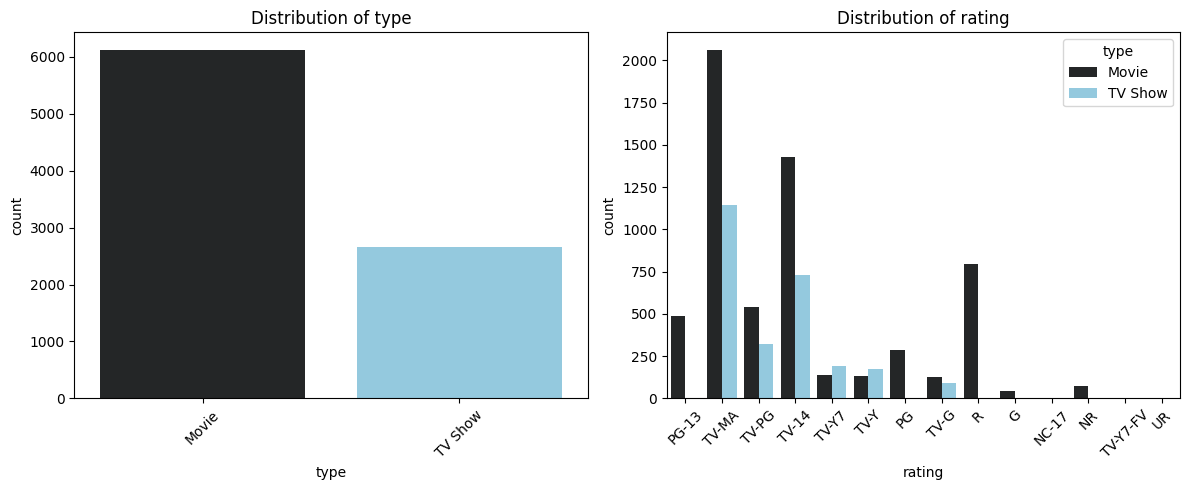

In [5]:

cols = ['type', 'rating']

plt.figure(figsize=(12, 5))

for inx, col in enumerate(cols):
    plt.subplot(1, 2, inx + 1)

    sns.countplot(data=df, x=col, hue='type' ,color='skyblue')

    plt.title(f"Distribution of {col}")
    plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

Before: 
 Data type: object
After: 
 Data type: datetime64[ns]


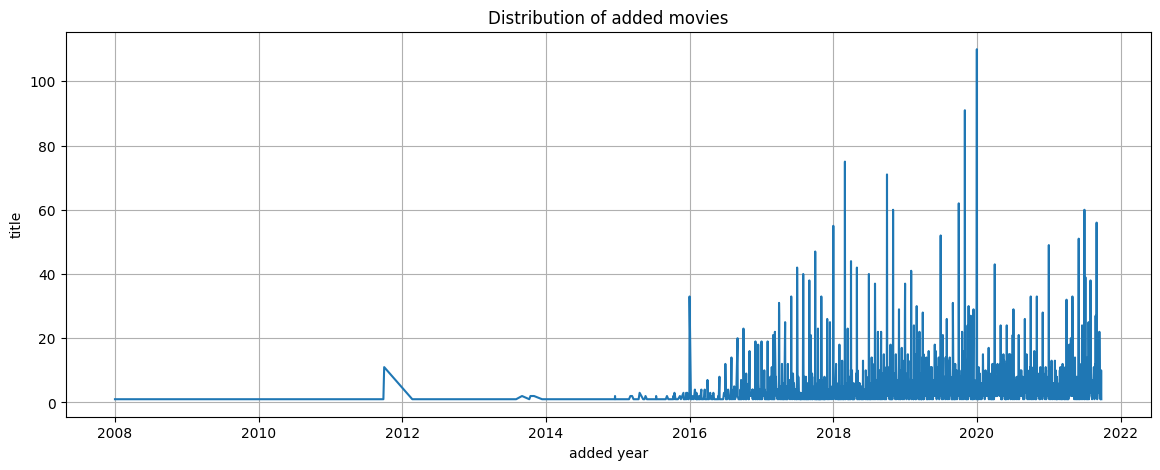

In [6]:
print('Before: \n Data type:', df['date_added'].dtype)

# converting into datetime
df['date_added'] = pd.to_datetime(df['date_added'])

print('After: \n Data type:', df['date_added'].dtype)

# Filtering date wise titles
movie_added = (
    df.groupby('date_added')
    ['title']
    .size()
    .sort_index()
    .reset_index(name='total_movies')
)

# Creating added movies plot

plt.figure(figsize=(14, 5))

plt.plot(
    movie_added['date_added'],
    movie_added['total_movies']
)

plt.title('Distribution of added movies')
plt.xlabel('added year')
plt.ylabel('title')
plt.grid()

plt.show()

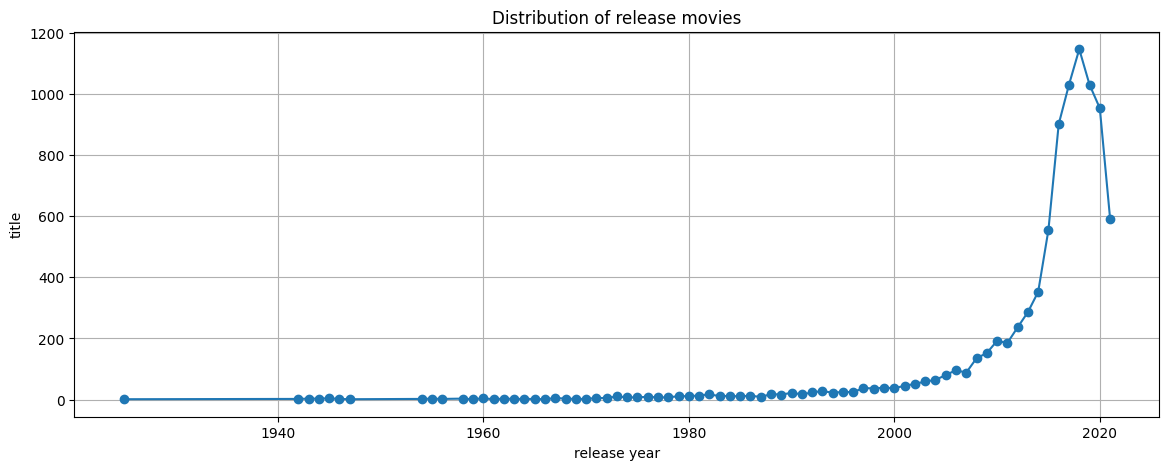

In [7]:
movie_release = (
    df.groupby('release_year')
    ['title']
    .size()
    .sort_index()
    .reset_index(name='total_movies')
)

# Creating release movies plot

plt.figure(figsize=(14, 5))

plt.plot(
    movie_release['release_year'],
    movie_release['total_movies'],
    marker ='o'
)

plt.title('Distribution of release movies')
plt.xlabel('release year')
plt.ylabel('title')
plt.grid()

plt.show()

In [8]:

# Top 10 country with movie and Tv show release

(
    df
    .groupby('country') ['type']
    .value_counts()
    .sort_values(ascending=False)
    .head(10)
    .to_frame()
)

,,count
country,type,
United States,Movie,2395
India,Movie,976
United States,TV Show,845
United Kingdom,Movie,387
Pakistan,TV Show,350
Not Given,Movie,257
United Kingdom,TV Show,251
Canada,Movie,187
Japan,TV Show,172


In [9]:

# Top 10 director with movie and Tv show release

(
    df
    .groupby('director') ['type']
    .value_counts()
    .sort_values(ascending=False)
    .head(10)
    .to_frame()
)

count
director               type          
Not Given              TV Show   2415
                       Movie      173
Rajiv Chilaka          Movie       19
Raúl Campos, Jan Suter Movie       18
Suhas Kadav            Movie       16
Marcus Raboy           Movie       15
Jay Karas              Movie       14
Alastair Fothergill    TV Show     14
Cathy Garcia-Molina    Movie       13
Youssef Chahine        Movie       12

In [10]:

# Top 10 listed_in with movie and Tv show release

(
    df
    .groupby('listed_in') ['type']
    .value_counts()
    .sort_values(ascending=False)
    .head(10)
    .to_frame()
)

,,count
listed_in,type,
"Dramas, International Movies",Movie,362
Documentaries,Movie,359
Stand-Up Comedy,Movie,334
"Comedies, Dramas, International Movies",Movie,274
"Dramas, Independent Movies, International Movies",Movie,252
Kids' TV,TV Show,219
Children & Family Movies,Movie,215
"Children & Family Movies, Comedies",Movie,201
"Documentaries, International Movies",Movie,186


In [11]:

# Top 10 duration with movie and Tv show release

(
    df
    .groupby('duration') ['type']
    .value_counts()
    .sort_values(ascending=False)
    .head(10)
    .to_frame()
)

,,count
duration,type,
1 Season,TV Show,1791
2 Seasons,TV Show,421
3 Seasons,TV Show,198
90 min,Movie,152
94 min,Movie,146
97 min,Movie,146
93 min,Movie,146
91 min,Movie,144
95 min,Movie,137


### Limitations of Predicting Netflix Content Success

After analyzing the dataset, I found that reliably predicting content success is not possible using the available features alone. The dataset contains metadata such as genre, country, release year, duration, and maturity rating, but lacks performance metrics such as viewership, total hours watched, revenue, and audience engagement. With these additional features, we could define success more clearly and build a more meaningful prediction model.

### Business Insights

* **Content Distribution:** Movies make up approximately 75% of the dataset, while TV shows account for around 25%, indicating a larger movie catalog.
* **Maturity Ratings:** TV-MA, TV-PG, and TV-14 are the most common ratings, suggesting that mature and teen-oriented content represents a significant portion of the catalog.
* **Content Addition Trends:** Netflix's content additions peaked around 2019–2020 and declined afterward. This shows a change in catalog additions, but does not necessarily mean demand decreased.
* **Release Year Trends:** Titles released around 2019 are highly represented, with fewer titles from later years.
* **Country Distribution:** The United States contributes the most titles, followed by India and the United Kingdom, highlighting the importance of these markets in the dataset.
* **Director Representation:** Rajiv Chilaka and Alastair Fothergill are among the directors with multiple titles in the dataset, showing repeated representation by certain creators.

**Conclusion:** These insights help us understand Netflix's content catalog and identify patterns that may support content planning. However, actual content success cannot be determined without performance-related data.
